## Data Cleaning, Analysis and Tend of Agricultural Yield Data

In [62]:
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns

## Q1:

In [63]:
crop_df = pd.read_csv(r"C:\Users\Danial Sherwani\Documents\IBA Material\Semester 1\Introduction To Computer Applications\ICA Assignments\Assignment 16\crop_yield.csv")

## Q2: 

In [64]:
crop_df.head(10)

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.0,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.0,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.0,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,NaN,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.0,05/01/2023,Faisalabad,Rabi,No,30000
5,F006,Rice,2000.0,6.0,06/01/2023,Faisalabad,Rabi,Yes,40000
6,F007,Maize,1500.0,6.0,07/01/2023,Faisalabad,Rabi,No,30000
7,F008,Wheat,1500.0,5.0,08/01/2023,Lahore,Rabi,No,30000
8,F009,Wheat,2000.0,5.0,09/01/2023,Faisalabad,Rabi,Yes,40000
9,F010,Wheat,1500.0,3.0,10/01/2023,Faisalabad,Rabi,Yes,30000


## Q3: 

In [65]:
cf.isnull().sum()

FARM_ID              0
CROP_TYPE            0
YIELD_KG           330
AREA_ACRES         144
HARVEST_DATE         0
DISTRICT           126
SEASON               0
FERTILIZER_USED    318
YIELD_VALUE          0
dtype: int64

## Q4: 

In [66]:
crop_df.dtypes

FARM_ID                str
CROP_TYPE              str
YIELD_KG           float64
AREA_ACRES         float64
HARVEST_DATE           str
DISTRICT               str
SEASON                 str
FERTILIZER_USED        str
YIELD_VALUE          int64
dtype: object

## Q5:

In [67]:
crop_df.describe()

,YIELD_KG,AREA_ACRES,YIELD_VALUE
count,2670.000000,2856.000000,3000.000000
mean,2014.232210,4.420168,39657.780000
std,407.846962,0.979259,8405.078755
min,1500.000000,3.000000,20068.000000
25%,1500.000000,4.000000,30000.000000
50%,2000.000000,4.000000,40000.000000
75%,2500.000000,5.000000,50000.000000
max,2500.000000,6.000000,50000.000000


## Q6:

In [68]:
crop_df.describe(exclude="number")

,FARM_ID,CROP_TYPE,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED
count,3000,3000,3000,2874,3000,2682
unique,3000,4,3000,4,2,2
top,F001,Wheat,01/01/2023,Faisalabad,Rabi,Yes
freq,1,1158,1,936,1528,1776


## Q7:

In [69]:
crop_df = crop_df.dropna(subset = ["YIELD_KG"])

## Q8:

In [70]:
crop_df["AREA_ACRES"] = crop_df["AREA_ACRES"].fillna(crop_df["AREA_ACRES"].mean())

## Q9:

In [71]:
crop_df["DISTRICT"] = crop_df["DISTRICT"].fillna("Unknown")

## Q10:

In [72]:
crop_df["FERTILIZER_USED"] = crop_df["FERTILIZER_USED"].fillna("No")

## Q11:

In [73]:
crop_df["YIELD_VALUE"] = crop_df["YIELD_VALUE"].fillna(crop_df["YIELD_VALUE"].mean())

## Q12:

In [74]:
crop_df["HARVEST_DATE"] = pd.to_datetime(crop_df["HARVEST_DATE"], format="%d/%m/%Y", errors="coerce")

## Q13:

In [75]:
crop_df["FARM_ID"] = crop_df["FARM_ID"].str.replace("F", "").astype(int)

## Q14:

In [76]:
crop_df.isnull().sum()

FARM_ID            0
CROP_TYPE          0
YIELD_KG           0
AREA_ACRES         0
HARVEST_DATE       0
DISTRICT           0
SEASON             0
FERTILIZER_USED    0
YIELD_VALUE        0
dtype: int64

## Q15:

In [77]:
crop_df.dtypes

FARM_ID                     int64
CROP_TYPE                     str
YIELD_KG                  float64
AREA_ACRES                float64
HARVEST_DATE       datetime64[us]
DISTRICT                      str
SEASON                        str
FERTILIZER_USED               str
YIELD_VALUE                 int64
dtype: object

## Q16:

In [78]:
yield_by_crop = crop_df.groupby("CROP_TYPE", as_index=False).agg({"YIELD_KG": "sum"})
print(yield_by_crop)

   CROP_TYPE   YIELD_KG
0      Maize  1112500.0
1       Rice  1638000.0
2  Sugarcane   592000.0
3      Wheat  2035500.0


## Q17:

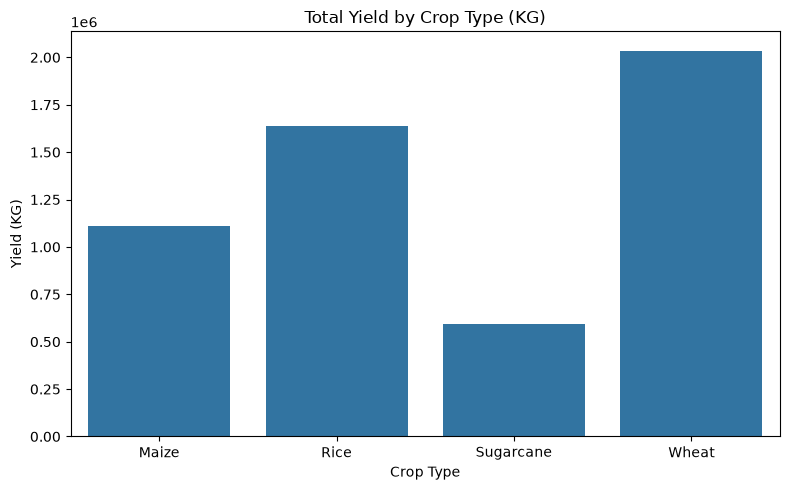

In [79]:
plt.figure(figsize=(8, 5))
sns.barplot(data=yield_by_crop, x="CROP_TYPE", y="YIELD_KG")
plt.title("Total Yield by Crop Type (KG)")
plt.xlabel("Crop Type")
plt.ylabel("Yield (KG)")
plt.tight_layout()
plt.show()

## Q18:

              YIELD_KG
HARVEST_DATE          
2023-01-01      1500.0
2023-01-02      1500.0
2023-01-03      2500.0
2023-01-04      1500.0
2023-01-05      1500.0
...                ...
2031-03-15      1500.0
2031-03-16      2000.0
2031-03-17      2000.0
2031-03-18      2000.0
2031-03-19      2500.0

[2670 rows x 1 columns]


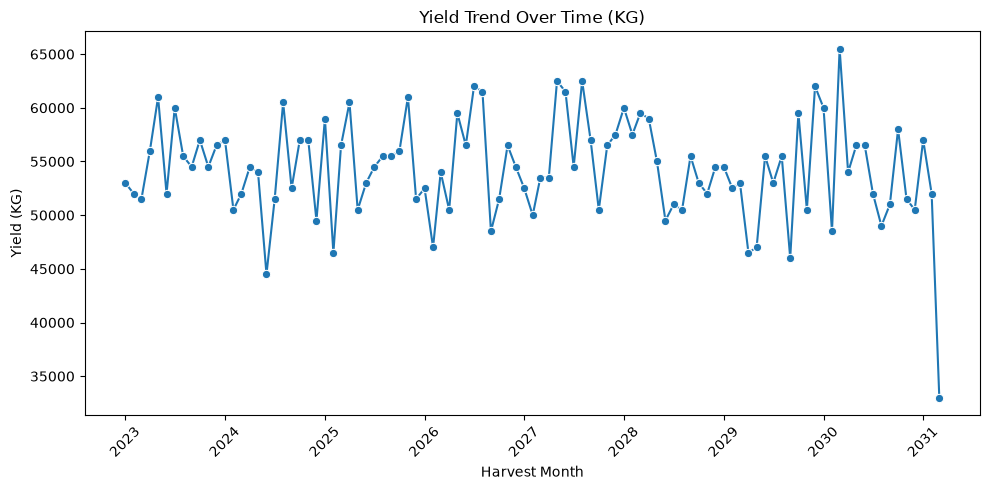

In [80]:
yield_pivot = crop_df.pivot_table(values="YIELD_KG", index="HARVEST_DATE", aggfunc="sum")
print(yield_pivot)
monthly_yield = yield_pivot.resample("MS").sum()
plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly_yield, x=monthly_yield.index, y="YIELD_KG", marker="o")
plt.title("Yield Trend Over Time (KG)")
plt.xlabel("Harvest Month")
plt.ylabel("Yield (KG)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("crop_yield_trend.png")
plt.show()